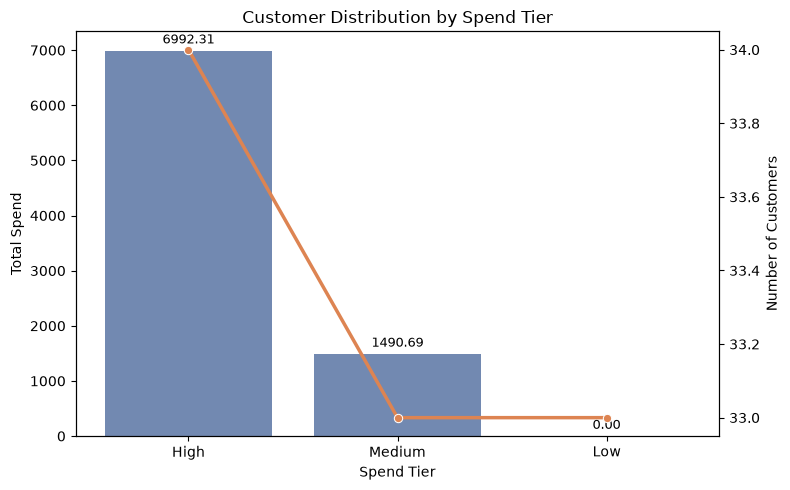

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.container import BarContainer

# Load query from queries/clv_analysis.sql and execute
base_dir = Path.cwd()
db_path = base_dir / "data" / "store.db"

# Jupyter may run from the project root or from the notebooks folder
if not db_path.exists():
    db_path = (base_dir.parent / "data" / "store.db").resolve()

conn = sqlite3.connect(str(db_path))
query_path = base_dir / "queries" / "clv_analysis.sql"
if not query_path.exists():
    query_path = (base_dir.parent / "queries" / "clv_analysis.sql").resolve()

with open(query_path, "r", encoding="utf-8") as f:
    query = f.read()
df = pd.read_sql_query(query, conn)
conn.close()

plt.figure(figsize=(8, 5))
tier_summary = (
    df.groupby("value_tier", observed=True)
    .agg(total_spend=("total_order_spend", "sum"))
    .reindex(["High", "Medium", "Low"])
)

if "customer_id" in df.columns:
    customer_counts = df.groupby("value_tier", observed=True)["customer_id"].nunique()
else:
    customer_counts = df.groupby("value_tier", observed=True).size()

tier_summary["customer_count"] = customer_counts.reindex(tier_summary.index).values

ax = sns.barplot(
    data=tier_summary.reset_index(),
    x="value_tier",
    y="total_spend",
    order=["High", "Medium", "Low"],
    color="#4C72B0",
    alpha=0.85
)

ax2 = ax.twinx()
plot_df = tier_summary.reset_index()
plot_df["value_tier"] = pd.Categorical(
    plot_df["value_tier"],
    categories=["High", "Medium", "Low"],
    ordered=True
)

sns.lineplot(
    data=plot_df,
    x="value_tier",
    y="customer_count",
    ax=ax2,
    marker="o",
    color="#DD8452",
    linewidth=2.5
)

ax.set_xlabel("Spend Tier")
ax.set_ylabel("Total Spend")
ax2.set_ylabel("Number of Customers")
ax.set_title("Customer Distribution by Spend Tier")

# Add labels above each bar
for container in ax.containers:
    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9, color="black")

plt.tight_layout()
project_root = base_dir if (base_dir / "data").exists() else base_dir.parent
fig_path = project_root / "notebooks" / "clv_distribution.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=300)
plt.show()

In [8]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import plotly.express as px

with sqlite3.connect(str(db_path)) as map_conn:
    locations = pd.read_sql_query(
        "SELECT customer_id, city, state, country FROM customers "
        "WHERE city IS NOT NULL AND state IS NOT NULL",
        map_conn,
    )

geolocator = Nominatim(user_agent="ecommerce-clv-map")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)
place_names = locations[["city", "state", "country"]].fillna("").agg(", ".join, axis=1)
locations["geo"] = place_names.apply(geocode)
locations = locations.dropna(subset=["geo"]).copy()
locations["latitude"] = locations["geo"].apply(lambda place: place.latitude)
locations["longitude"] = locations["geo"].apply(lambda place: place.longitude)

map_df = (
    df.merge(locations[["customer_id", "latitude", "longitude"]], on="customer_id")
    .dropna(subset=["latitude", "longitude"])
    .groupby(["latitude", "longitude"], as_index=False)
    .agg(total_spend=("total_order_spend", "sum"))
)

fig = px.scatter_map(
    map_df,
    lat="latitude",
    lon="longitude",
    size="total_spend",
    color="total_spend",
    hover_data={"total_spend": ":.2f"},
    color_continuous_scale="YlOrRd",
    size_max=30,
    zoom=3,
    center={"lat": 39.5, "lon": -98.35},
    map_style="open-street-map",
    title="Customer Spend by City/State",
)
map_path = base_dir / "customer_spend_map.html"
fig.show()